# 3. Tokenização

**Pergunta deste notebook:** como transformar uma música (4 canais em paralelo) numa fila única de símbolos, que é o que uma rede autorregressiva sabe prever?

Um modelo autorregressivo prevê o próximo símbolo (token) a partir dos anteriores. Então a partitura precisa virar uma sequência, e existem várias formas de fazer isso. O `src/tokenizer.py` tem três, todas reversíveis (dá para voltar dos tokens à música):

| Modo | Ideia | Lembra o quê |
|---|---|---|
| **nlm** | lista de **eventos** no tempo: "liga nota", "espera N ticks", "desliga nota" | MIDI |
| **grid_unrolled** | a **grade** do tracker escrita por extenso: para cada canal, passo por passo | o editor do PICO-8 |
| **grid_block** | a grade, mas cada trecho (SFX) é **definido uma vez** e depois só **referenciado** | o editor do PICO-8, com seus SFX reutilizados |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import nbkit as k

k.estilo()
reais = k.musicas_reais(300)
musica = reais[154]
toks = {modo: k.tokenizador(modo) for modo in ("nlm", "grid_unrolled", "grid_block")}

## A mesma música nos três modos

Primeiro o **nlm**. Leia como uma fila de acontecimentos: escolhe instrumento e volume do canal 1, liga uma nota, espera (`WT_n` = n ticks), desliga.

In [2]:
k.mostrar_tokens(toks["nlm"].encode_song(musica), n=40)

BOS               LOOP_START        PATTERN_START     REF_SPEED_16      CH1_INST_2        CH1_VOL_3         CH1_FX_7          CH1_NOTEON_17   
CH2_INST_0        CH2_VOL_5         CH2_NOTEON_5      CH3_INST_0        CH3_VOL_5         CH3_FX_3          CH3_NOTEON_21     WT_16           
CH1_VOL_2         CH1_NOTEON_21     CH2_NOTEOFF       CH3_NOTEOFF       WT_16             CH1_VOL_1         CH1_NOTEON_24     CH2_NOTEON_17   
WT_16             CH1_NOTEON_21     CH2_NOTEOFF       WT_16             CH1_VOL_3         CH1_NOTEON_17     CH2_NOTEON_5      CH3_INST_6      
CH3_VOL_3         CH3_NOTEON_33     WT_16             CH1_VOL_2         CH1_NOTEON_21     CH2_NOTEOFF       CH3_NOTEOFF       WT_16           
... (893 tokens no total)


Agora o **grid_unrolled**: para cada canal (`CH1_START`), a velocidade e depois cada passo com som (`STEP`, `PITCH`, `INST`, `VOL`, e `FX` quando há efeito).

In [3]:
k.mostrar_tokens(toks["grid_unrolled"].encode_song(musica), n=40)

BOS               LOOP_START        PATTERN_START     REF_SPEED_16      CH1_START         SPEED_16          STEP_0            PITCH_17        
INST_2            VOL_3             FX_7              STEP_1            PITCH_21          INST_2            VOL_2             FX_7            
STEP_2            PITCH_24          INST_2            VOL_1             FX_7              STEP_3            PITCH_21          INST_2          
VOL_1             FX_7              STEP_4            PITCH_17          INST_2            VOL_3             FX_7              STEP_5          
PITCH_21          INST_2            VOL_2             FX_7              STEP_6            PITCH_24          INST_2            VOL_1           
... (1602 tokens no total)


Por fim o **grid_block**. O conteúdo de um trecho aparece uma vez, entre `CHc_DEF_BLOCK_b` e `END_BLOCK`. Quando o mesmo trecho volta, basta um token: `CHc_USE_BLOCK_b`.

In [4]:
ids_bloco = toks["grid_block"].encode_song(musica)
k.mostrar_tokens(ids_bloco, n=24)
defs = sum("DEF_BLOCK" in t for t in ids_bloco)
usos = sum("USE_BLOCK" in t for t in ids_bloco)
print(f"\nnesta música: {defs} trechos definidos, {usos} reutilizações com um único token")

BOS               LOOP_START        PATTERN_START     REF_SPEED_16      CH1_DEF_BLOCK_0   SPEED_16          STEP_0            PITCH_17        
INST_2            VOL_3             FX_7              STEP_1            PITCH_21          INST_2            VOL_2             FX_7            
STEP_2            PITCH_24          INST_2            VOL_1             FX_7              STEP_3            PITCH_21          INST_2          
... (541 tokens no total)

nesta música: 5 trechos definidos, 13 reutilizações com um único token


## Quantos tokens cada modo gasta

Música de PICO-8 repete muito. O grid_block aproveita a repetição; os outros dois escrevem tudo de novo.

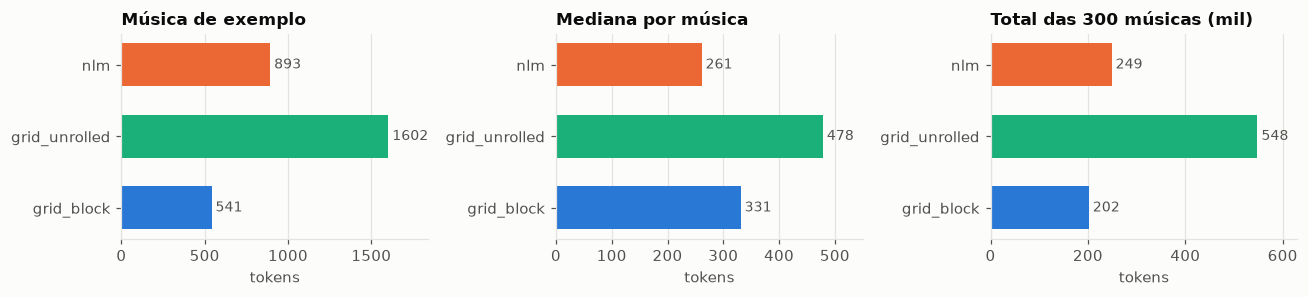

In [5]:
comp = {modo: np.array([len(t.encode_song(m)) for m in reais]) for modo, t in toks.items()}
cores = {"nlm": k.LARANJA, "grid_unrolled": k.VERDE, "grid_block": k.AZUL}
paineis = [("Música de exemplo", {m: len(toks[m].encode_song(musica)) for m in comp}),
           ("Mediana por música", {m: np.median(comp[m]) for m in comp}),
           ("Total das 300 músicas (mil)", {m: comp[m].sum() / 1000 for m in comp})]

fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, (titulo, valores) in zip(axes, paineis):
    for modo, v in valores.items():
        ax.barh(modo, v, color=cores[modo], height=0.6)
        ax.text(v, modo, f" {v:.0f}", va="center", fontsize=9, color=k.TINTA2)
    ax.set_title(titulo, loc="left"); ax.invert_yaxis(); ax.set_xlabel("tokens")
    ax.grid(axis="y", visible=False); ax.set_xlim(0, max(valores.values()) * 1.15)
fig.tight_layout()
plt.show()

Leitura:

- O **grid_unrolled** é sempre o mais longo: escreve passo por passo, sem atalho.
- O **grid_block** tem um custo fixo para definir cada trecho. Em música curta, sem repetição, ele gasta um pouco mais que o nlm (veja a mediana). Em música longa, que repete trechos, gasta bem menos (veja o exemplo).
- No total, o grid_block é o mais compacto, e é nas músicas longas que o tamanho da sequência mais atrapalha uma LSTM.

## O vocabulário

O vocabulário é o conjunto de todos os tokens possíveis. O modelo escolhe um deles a cada passo.

In [6]:
linhas = []
for modo, t in toks.items():
    cont = Counter(k.categoria(x) for x in t.token_to_id)
    linhas.append({"modo": modo, "vocabulário": t.vocab_size,
                   "maiores famílias": ", ".join(f"{nome} ({n})" for nome, n in cont.most_common(3))})
k.tabela(linhas)

| modo | vocabulário | maiores famílias |
|---|---|---|
| nlm | 709 | nota liga (256), velocidade (255), espera (64) |
| grid_unrolled | 1151 | passo (544), velocidade (510), altura (64) |
| grid_block | 1250 | bloco (579), velocidade (510), passo (64) |

No nlm, o canal faz parte do token (`CH2_NOTEON_16`), então há 4 cópias de cada evento. Nos modos de grade, o canal é dito uma vez (`CH2_START`) e os tokens de nota são compartilhados. O grid_block tem ainda os tokens de definir e usar bloco.

## Ida e volta

Tokenizar e destokenizar tem que devolver a mesma música. Conferimos em 100 músicas, comparando o que soa em cada canal a cada tick (altura, instrumento e volume).

Comparamos por tick, e não nota a nota, porque o nlm só guarda eventos no tempo: um canal com notas de duração dobrada volta escrito na grade de referência do pattern, com cada nota repetida duas vezes. O som é o mesmo; a escrita, não.

In [7]:
def soando(m):
    """Para cada pattern e canal, o que soa em cada tick."""
    out = []
    for pat in m["patterns"]:
        for c in range(1, 5):
            ch = pat["channels"].get(f"ch{c}") or {}
            linha = [None] * int(pat["pattern_ticks"])
            if ch.get("active"):
                passo = int(ch.get("speed") or pat["ref_speed"])
                for i, n in enumerate(ch.get("notes_unrolled") or []):
                    if n["volume"] > 0:
                        trecho = slice(i * passo, (i + 1) * passo)
                        linha[trecho] = [(n["pitch"], n["instrument"], n["volume"])] * len(linha[trecho])
            out.append(linha)
    return out

for modo, t in toks.items():
    iguais = sum(soando(t.decode_ids(t.encode_song_to_ids(m))) == soando(m) for m in reais[:100])
    print(f"{modo:>14}: {iguais}/100 músicas idênticas depois da ida e volta")

           nlm: 100/100 músicas idênticas depois da ida e volta
 grid_unrolled: 100/100 músicas idênticas depois da ida e volta


    grid_block: 100/100 músicas idênticas depois da ida e volta


## O que decidimos e por quê

Treinamos a mesma LSTM com **nlm** e com **grid_block**:

- o **nlm** é a representação por eventos mais comum na literatura (referência);
- o **grid_block** é a que mais se parece com a forma como a música é escrita no PICO-8, e encurta as músicas longas, as mais difíceis para uma LSTM.

O grid_unrolled ficou como opção não treinada (o tempo de cluster foi para os outros dois).

Um aviso que volta no próximo notebook: como os vocabulários são diferentes, **loss e perplexidade não comparam nlm com grid_block**. Para comparar os dois usamos bits por segundo de música.

**Experimente:** troque `reais[154]`; procure uma música em que o grid_block não ganha nada (sem repetição); decodifique uma lista de tokens editada por você com `toks["nlm"].decode_tokens(...)` e ouça com `k.tocar(...)`.

Anterior: [2. Filtros e divisão](02_filtros_e_split.ipynb) · Próximo: [4. Treino](04_treino.ipynb).